In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
FIGURES_DIR = ROOT / "output" / "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

raw_data = {
    "< 50 lat": {"unvax_pop": 1_116_834, "vax_pop": 3_501_118, "unvax_sev": 43,  "vax_sev": 11},
    "50+ lat":  {"unvax_pop": 186_078,   "vax_pop": 2_133_516, "unvax_sev": 171, "vax_sev": 290},
}

tot_unvax_pop = sum(v["unvax_pop"] for v in raw_data.values())
tot_vax_pop   = sum(v["vax_pop"]   for v in raw_data.values())
tot_unvax_sev = sum(v["unvax_sev"] for v in raw_data.values())
tot_vax_sev   = sum(v["vax_sev"]   for v in raw_data.values())

raw_data["Ogółem"] = {
    "unvax_pop": tot_unvax_pop,
    "vax_pop":   tot_vax_pop,
    "unvax_sev": tot_unvax_sev,
    "vax_sev":   tot_vax_sev,
}

stats = {}
for k, v in raw_data.items():
    r_unvax = v["unvax_sev"] / v["unvax_pop"] * 100_000
    r_vax   = v["vax_sev"]   / v["vax_pop"]   * 100_000
    ve      = (1 - r_vax / r_unvax) * 100
    stats[k] = {"r_unvax": r_unvax, "r_vax": r_vax, "ve": ve}

COLOR_BAD       = "#C0392B"
COLOR_BAD_TITLE = "#7B1E14"
COLOR_GRAY      = "#7F8C8D"
COLOR_UNVAX     = "#D55E00"
COLOR_VAX       = "#009E73"

plt.style.use("default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.9,
})

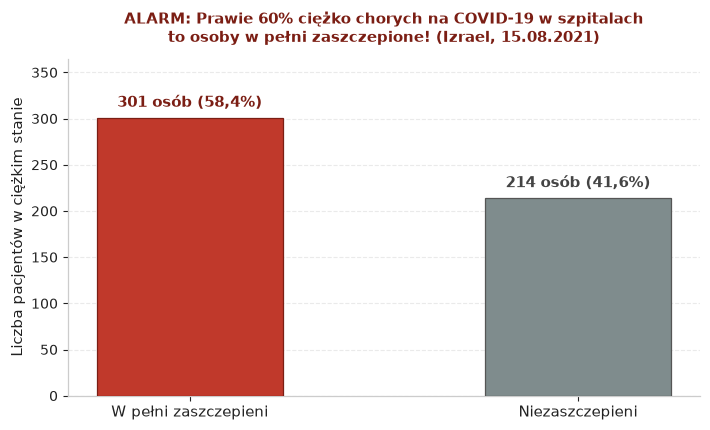

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))

labels_bad = ["W pełni zaszczepieni", "Niezaszczepieni"]
counts_bad = [tot_vax_sev, tot_unvax_sev]
shares_bad = [c / (tot_vax_sev + tot_unvax_sev) * 100 for c in counts_bad]
colors_bad = [COLOR_BAD, COLOR_GRAY]

bars = ax.bar(
    labels_bad, counts_bad, width=0.48,
    color=colors_bad, edgecolor=["#7B1E14", "#555555"], linewidth=0.9, zorder=3
)

ax.set_ylim(0, 365)
ax.set_ylabel("Liczba pacjentów w ciężkim stanie", fontsize=10.5)
ax.set_title(
    "ALARM: Prawie 60% ciężko chorych na COVID-19 w szpitalach\n"
    "to osoby w pełni zaszczepione! (Izrael, 15.08.2021)",
    fontsize=11, fontweight="bold", color=COLOR_BAD_TITLE, pad=12
)

ax.yaxis.grid(True, linestyle="--", alpha=0.6, color="#DCDCDC", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", labelsize=10.5)
ax.tick_params(axis="y", labelsize=10)

for bar, cnt, sh, col in zip(bars, counts_bad, shares_bad, [COLOR_BAD_TITLE, "#444444"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        cnt + 8,
        f"{cnt} osób ({sh:.1f}%)".replace(".", ","),
        ha="center", va="bottom",
        fontsize=10.5, fontweight="bold", color=col
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "covid_bad.pdf", format="pdf", bbox_inches="tight")
plt.show()

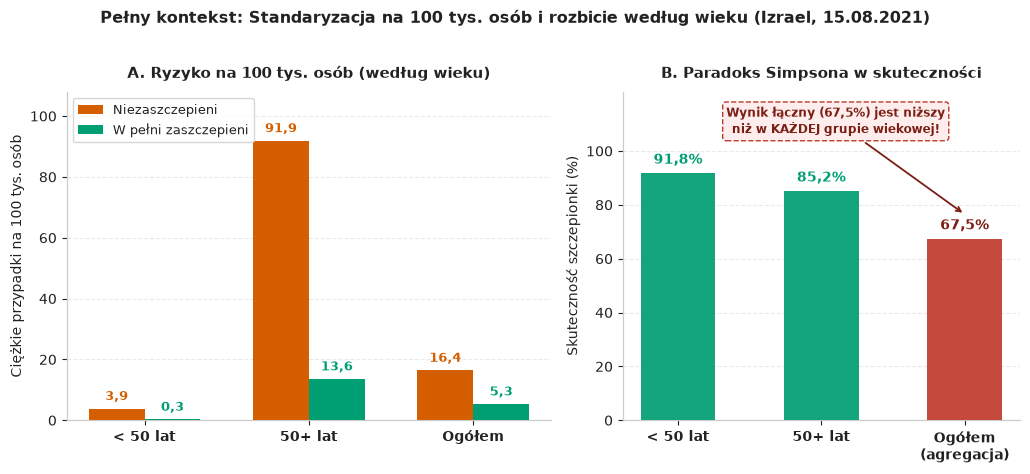

In [3]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10.4, 4.6),
    gridspec_kw={"width_ratios": [1.22, 1.0]}
)

groups = ["< 50 lat", "50+ lat", "Ogółem"]
x = np.arange(len(groups))
w = 0.34

unvax_rates = [stats[g]["r_unvax"] for g in groups]
vax_rates   = [stats[g]["r_vax"]   for g in groups]

b1 = ax1.bar(x - w/2, unvax_rates, width=w, color=COLOR_UNVAX, label="Niezaszczepieni", zorder=3)
b2 = ax1.bar(x + w/2, vax_rates,   width=w, color=COLOR_VAX,   label="W pełni zaszczepieni", zorder=3)

ax1.set_xticks(x)
ax1.set_xticklabels(groups, fontsize=10, fontweight="bold")
ax1.set_ylim(0, 108)
ax1.set_ylabel("Ciężkie przypadki na 100 tys. osób", fontsize=10)
ax1.set_title("A. Ryzyko na 100 tys. osób (według wieku)", fontsize=10.5, fontweight="bold", pad=10)
ax1.yaxis.grid(True, linestyle="--", alpha=0.6, color="#DCDCDC", zorder=0)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9)

for bars_grp, col in [(b1, COLOR_UNVAX), (b2, COLOR_VAX)]:
    for bar in bars_grp:
        h = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2, h + 1.8,
            f"{h:.1f}".replace(".", ","),
            ha="center", va="bottom", fontsize=9.2, fontweight="bold", color=col
        )

ve_vals = [stats[g]["ve"] for g in groups]
bar_cols = [COLOR_VAX, COLOR_VAX, COLOR_BAD]

b3 = ax2.bar(x, ve_vals, width=0.52, color=bar_cols, alpha=0.92, zorder=3)
ax2.set_xticks(x)
ax2.set_xticklabels(["< 50 lat", "50+ lat", "Ogółem\n(agregacja)"], fontsize=9.8, fontweight="bold")
ax2.set_ylim(0, 122)
ax2.set_yticks([0, 20, 40, 60, 80, 100])
ax2.set_ylabel("Skuteczność szczepionki (%)", fontsize=10)
ax2.set_title("B. Paradoks Simpsona w skuteczności", fontsize=10.5, fontweight="bold", pad=10)
ax2.yaxis.grid(True, linestyle="--", alpha=0.6, color="#DCDCDC", zorder=0)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

for bar, val, col in zip(b3, ve_vals, [COLOR_VAX, COLOR_VAX, COLOR_BAD_TITLE]):
    ax2.text(
        bar.get_x() + bar.get_width() / 2, val + 2.2,
        f"{val:.1f}%".replace(".", ","),
        ha="center", va="bottom", fontsize=10, fontweight="bold", color=col
    )

ax2.annotate(
    "Wynik łączny (67,5%) jest niższy\nniż w KAŻDEJ grupie wiekowej!",
    xy=(2, ve_vals[2] + 9),
    xytext=(1.1, 111),
    arrowprops=dict(arrowstyle="->", color=COLOR_BAD_TITLE, lw=1.3),
    fontsize=8.5, fontweight="bold", color=COLOR_BAD_TITLE, ha="center", va="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#FDEDEC", edgecolor=COLOR_BAD, linestyle="--", lw=1.0)
)

fig.suptitle(
    "Pełny kontekst: Standaryzacja na 100 tys. osób i rozbicie według wieku (Izrael, 15.08.2021)",
    fontsize=11.5, fontweight="bold", y=1.02
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "covid_good.pdf", format="pdf", bbox_inches="tight")
plt.show()